# 05 · Evaluación por hoja

## Objetivo
Comparar, en cada hoja, el caudal de operación con los límites escritos en esa hoja y el PIP calculado con el PIP cacheado.

## Alcance
No se ajusta una curva común a las cinco hojas. No hay referencia de PIP distinta de la caché del mismo libro, así que no hay error de predicción.


pozo QF-084 hoja QF-554H
  Q_operacion_BFPD 10301.0
  Q_prueba_BFPD 10301.0
  Qmin_BFPD 2500.0 Qmax_BFPD 10000.0
  regla RC-BES-01 por_encima_del_limite_maximo revision pendiente
  diff_pip_ft 0.0
  fecha_cache 2026-10-17 00:00:00
pozo QF-301 hoja QF-545H
  Q_operacion_BFPD 8767.0
  Q_prueba_BFPD 8767.0
  Qmin_BFPD 2500.0 Qmax_BFPD 10000.0
  regla RC-BES-03 dentro_de_los_limites_escritos revision pendiente
  diff_pip_ft 0.0
  fecha_cache 2026-10-17 00:00:00
pozo QF-147 hoja QF-500H
  Q_operacion_BFPD 7728.0
  Q_prueba_BFPD 7728.0
  Qmin_BFPD 2500.0 Qmax_BFPD 10000.0
  regla RC-BES-03 dentro_de_los_limites_escritos revision pendiente
  diff_pip_ft 0.0
  fecha_cache 2026-10-17 00:00:00
pozo QF-005 hoja QF-378HST
  Q_operacion_BFPD 7116.0
  Q_prueba_BFPD 7094.400000000001
  Qmin_BFPD 2000.0 Qmax_BFPD 8000.0
  regla RC-BES-03 dentro_de_los_limites_escritos revision pendiente
  diff_pip_ft 0.0
  fecha_cache 2026-10-17 00:00:00
pozo QF-306 hoja QF-549HST
  Q_operacion_BFPD 5419.0
  Q_prueba_

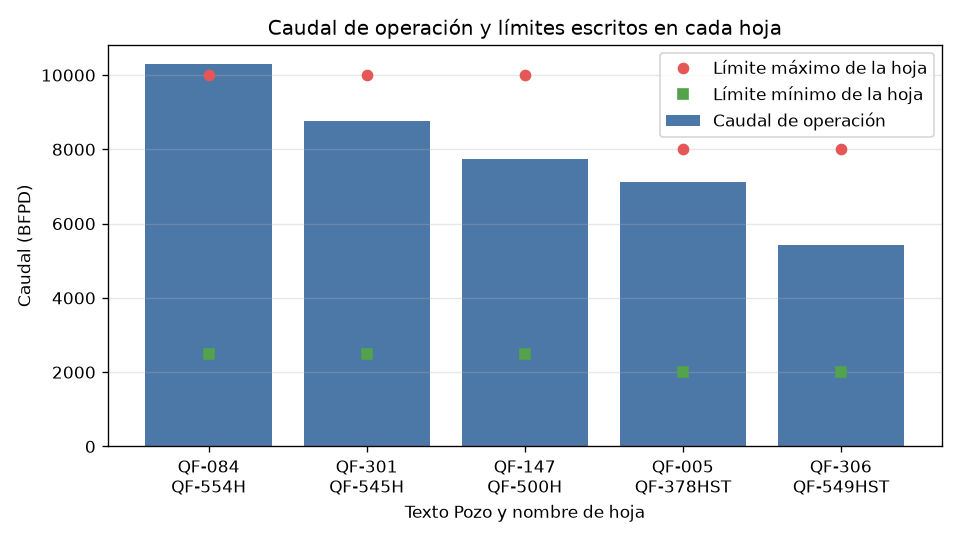

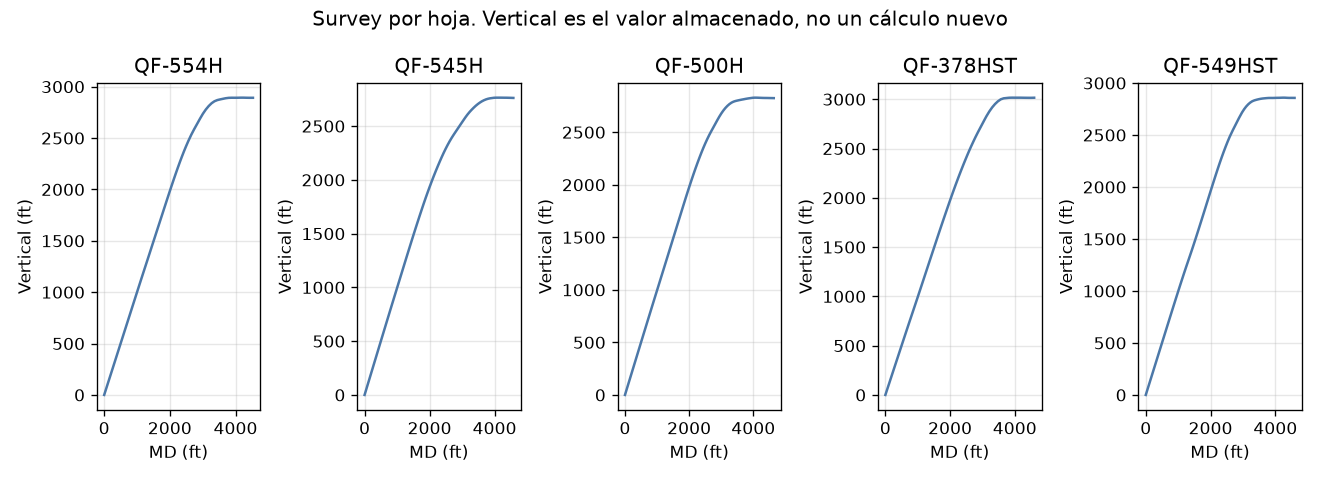

In [1]:
from pathlib import Path
import os, sys
aqui = Path.cwd().resolve()
expediente = next(c for c in [aqui, *aqui.parents] if (c / "dataset.md").is_file() and (c / "entrada").is_dir())
os.chdir(expediente)
if str(expediente / "src") not in sys.path:
    sys.path.insert(0, str(expediente / "src"))
libro = expediente / "entrada" / "BES_jun.xlsx"

from ingesta.leer_bes_jun import leer_libro
from modelo_deterministico.fluidos_bes_jun import evaluar_fluido
from modelo_deterministico.balance_bes_jun import evaluar_balance
from reglas.candidatas_bes_jun import comparar_caudal_con_limites
from IPython.display import Image, display
hojas = leer_libro(libro)
for hoja in hojas:
    fluido = evaluar_fluido(hoja["api_deg"], hoja["temperatura_c"], hoja["bsw_numero"], hoja["densidad_agua_lb_gal"])
    bal = evaluar_balance(
        hoja["presion_sensor_psi"], hoja["thp_psi"], hoja["tvd_intake_ft"], hoja["tvd_sensor_ft"],
        hoja["tvd_descarga_ft"], fluido.resultados["gradiente_psi_ft"]["valor"],
        hoja["caudal_operacion_bfpd"], hoja["id_tubing_in"],
    )
    regla = comparar_caudal_con_limites(hoja)[0]
    print("pozo", hoja["pozo"], "hoja", hoja["hoja"])
    print("  Q_operacion_BFPD", hoja["caudal_operacion_bfpd"])
    print("  Q_prueba_BFPD", hoja["caudal_prueba_bfpd"])
    print("  Qmin_BFPD", hoja["limite_minimo_bfpd"], "Qmax_BFPD", hoja["limite_maximo_bfpd"])
    print("  regla", regla["id"], regla["resultado"], "revision", regla["estado_revision"])
    print("  diff_pip_ft", abs(bal.resultados["pip_ft"]["valor"] - hoja["cache_pip_ft"]))
    print("  fecha_cache", hoja["fecha_cache"])
display(Image(filename="reports/figuras/caudal_limites_por_hoja.png"))
display(Image(filename="reports/figuras/survey_md_tvd_por_hoja.png"))


## Métrica usada
Para el caudal, la comparación es ordinal: el caudal de operación de la hoja contra el mínimo y el máximo escritos en la misma hoja, ambos en BFPD. No es un error porcentual. QF-084, en QF-554H, queda en RC-BES-01 porque 10301 BFPD supera 10000 BFPD. Las otras cuatro hojas quedan en RC-BES-03. Las reglas salen con `estado_revision=pendiente`.

Para el PIP, la métrica es la diferencia absoluta en ft entre el valor calculado y la caché de la celda «PIP en (ft)». En las cinco hojas esa diferencia es 0 ft. La caché es el resultado que Excel ya guardó para la misma fórmula, no un sensor distinto. Por eso el contraste confirma la transcripción y no mide una predicción.

La figura de caudal usa barras para el caudal de operación y marcas para los límites de cada hoja. La figura del survey separa las hojas: el eje horizontal es la profundidad medida en ft y el vertical es el valor almacenado de Vertical, en ft. No se ajustó una trayectoria nueva.

Solo QF-378HST tiene caudal de prueba distinto del de operación (7094.4 BFPD y 7116 BFPD). La fecha cacheada de QF-549HST es 2017-09-06; las otras cuatro son 2026-10-17. No hay pares de instantes que permitan un pronóstico.
